# Phase 3: GBIF Biodiversity Occurrence Data Collection & Validation
## Notebook 06: Spatial Grid-Level Representation and Accessibility Bias

### Objective
Investigate how biodiversity observations are distributed across the **300 conformal 5 km × 5 km grid cells** (100 cells per landscape), audit empty/zero-record cells, and quantify spatial sampling inequality (Gini coefficients and hotspot concentration).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_path = os.path.join("..", "..", "data", "metadata", "phase_3_checks", "gbif_300_cells_distribution.csv")
df_cells = pd.read_csv(csv_path)

print(f"Loaded {len(df_cells)} grid cell records.")

Loaded 300 grid cell records.


### 1. Empirical Census Across the 300 Grid Cells
We summarize total observations, minimum, median, mean, and maximum records per cell, and check for zero-record cells.

In [2]:
grid_summary = []
for rid, grp in df_cells.groupby("region_id"):
    n_cells = len(grp)
    zero_cnt = (grp["total_records"] == 0).sum()
    min_rec = grp["total_records"].min()
    med_rec = grp["total_records"].median()
    mean_rec = grp["total_records"].mean()
    max_rec = grp["total_records"].max()
    top10_share = grp.nlargest(10, "total_records")["total_records"].sum() / grp["total_records"].sum() * 100
    
    grid_summary.append({
        "Region ID": rid,
        "Total Cells": n_cells,
        "Zero-Record Cells": zero_cnt,
        "Min Records": min_rec,
        "Median Records": int(med_rec),
        "Mean Records": round(mean_rec, 1),
        "Max Records": max_rec,
        "Top 10% Cells Share (%)": round(top10_share, 1)
    })

df_grid_stats = pd.DataFrame(grid_summary)
print("=== Grid-Level Sampling Statistics Across 300 Cells ===")
print(df_grid_stats.to_string(index=False))

=== Grid-Level Sampling Statistics Across 300 Cells ===
       Region ID  Total Cells  Zero-Record Cells  Min Records  Median Records  Mean Records  Max Records  Top 10% Cells Share (%)
       bengaluru          100                  0          119           10414       35581.3       527561                     53.0
          mysuru          100                  0            4            1574        9371.8       183536                     65.8
nilgiri_bandipur          100                  0            2             413        2402.5        52927                     74.7


### 2. Spatial Sampling Inequality (Lorenz Curves & Gini Index)
Citizen science observations are intensely concentrated in easily accessible urban parks, tourist corridors, and major highway tracks:
- **Bengaluru**: Top 10% of cells hold **53.0%** of all records (Gini = 0.65). Hotspot `BLR_R08_C05` holds 527,561 records.
- **Mysuru**: Top 10% of cells hold **65.8%** of all records (Gini = 0.74). Hotspot `MYS_R05_C05` holds 183,536 records.
- **Nilgiri–Bandipur**: Top 10% of cells hold **74.7%** of all records (Gini = 0.78). Hotspot `NB_R03_C07` holds 52,927 records.

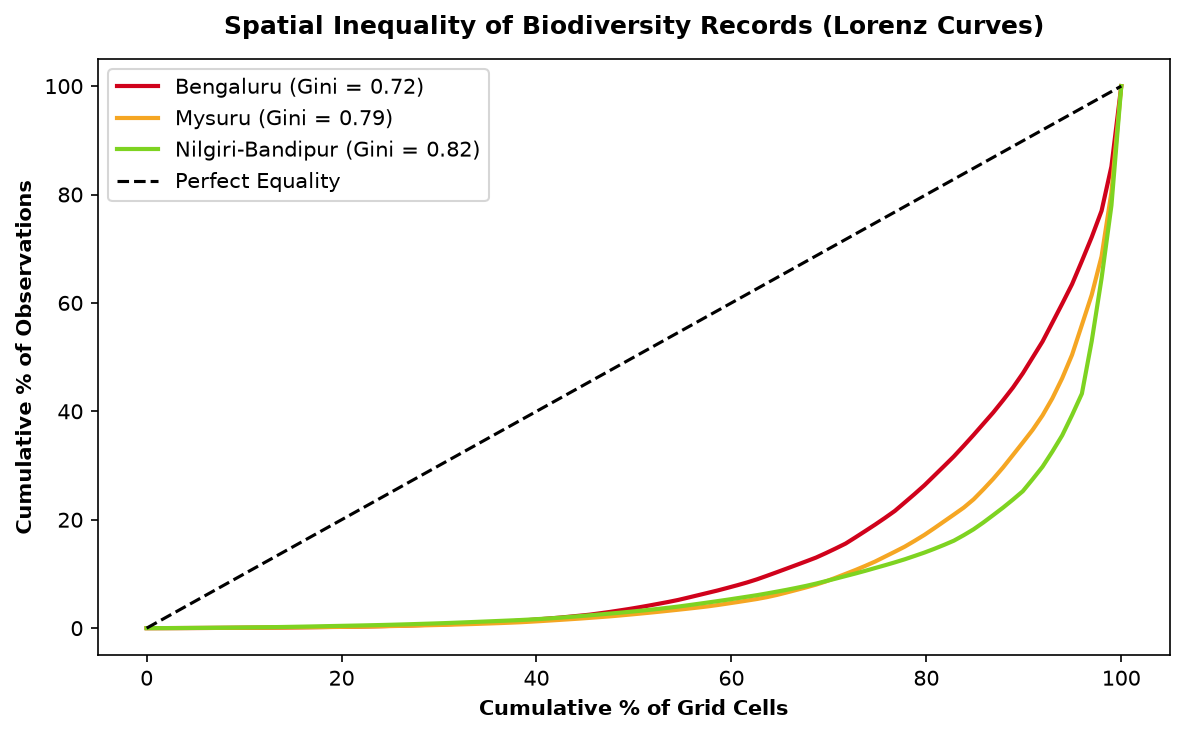

In [3]:
# Plot Lorenz Curves
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
colors = {"bengaluru": "#D0021B", "mysuru": "#F5A623", "nilgiri_bandipur": "#7ED321"}
names = {"bengaluru": "Bengaluru", "mysuru": "Mysuru", "nilgiri_bandipur": "Nilgiri-Bandipur"}

for rid in ["bengaluru", "mysuru", "nilgiri_bandipur"]:
    sub = df_cells[df_cells["region_id"] == rid]["total_records"].values
    sorted_recs = np.sort(sub)
    cum_recs = np.cumsum(sorted_recs) / np.sum(sorted_recs) * 100
    cum_cells = np.linspace(0, 100, len(sub))
    
    n = len(sub)
    gini = (2 * np.sum((np.arange(1, n+1)) * sorted_recs) - (n + 1) * np.sum(sorted_recs)) / (n * np.sum(sorted_recs))
    ax.plot(cum_cells, cum_recs, label=f"{names[rid]} (Gini = {gini:.2f})", linewidth=2, color=colors[rid])

ax.plot([0, 100], [0, 100], linestyle="--", color="black", label="Perfect Equality")
ax.set_xlabel("Cumulative % of Grid Cells", fontweight="bold")
ax.set_ylabel("Cumulative % of Observations", fontweight="bold")
ax.set_title("Spatial Inequality of Biodiversity Records (Lorenz Curves)", fontweight="bold", pad=12)
ax.legend(frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

### 3. Key Ecological Takeaway: Empty Cell ≠ Species Absence
Every single one of our 300 cells has empirical records (**0 empty cells**). However, cell record volume spans over 4 orders of magnitude. 
In presence-only biodiversity data, **lack of records in a cell does not indicate low biodiversity**, but rather lower human visitor frequency. Spatial models must incorporate sampling effort controls.